# PSL Cricket Analytics — Exploratory Data Analysis (EDA)

**Project:** ETL + EDA Pipeline · **Data:** 357 completed Pakistan Super League (PSL) matches, 2016–2026

### Why this dataset?
PSL data has clear numeric measures (runs, wickets, balls, overs) and clear outcomes (who won). This makes it a good dataset for studying team performance, match results and individual player contributions.

### Where the data is loaded
The ETL pipeline (`src/`) extracts data from the **Big Balls Sports Data API**, transforms it with **Pandas**, validates every record with **Pydantic**, and loads it into:
- **CSV files** (`data/processed/`), which are easy to open and inspect
- an **SQLite database** (`cricket.db`), which gives structured storage that can be queried with SQL

### EDA plan
1. Data overview  2. Data quality (missing values, duplicates, checks)  3. Match and team analysis
4. Batting analysis  5. Bowling analysis  6. Key findings

## 1. Load the data

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# Read the processed CSV files made by the ETL pipeline
matches = pd.read_csv("../data/processed/matches.csv")
batting = pd.read_csv("../data/processed/batting.csv")
bowling = pd.read_csv("../data/processed/bowling.csv")

# Turn the date text into real dates, and add the season (year)
matches["match_date"] = pd.to_datetime(matches["match_date"])
matches["season"] = matches["match_date"].dt.year

print("Matches:", matches.shape, "| Batting:", batting.shape, "| Bowling:", bowling.shape)

Matches: (357, 10) | Batting: (5666, 11) | Bowling: (4200, 11)


The same data is also stored in **SQLite**. Here we read it back with an SQL query to show that the database works.

In [2]:
connection = sqlite3.connect("../data/processed/cricket.db")

query = """
    SELECT winner, COUNT(*) AS wins
    FROM matches
    WHERE winner IS NOT NULL
    GROUP BY winner
    ORDER BY wins DESC
"""
display(pd.read_sql_query(query, connection))

connection.close()

,winner,wins
0,Peshawar Zalmi,69
1,Islamabad United,69
2,Quetta Gladiators,55
3,Lahore Qalandars,54
4,Multan Sultans,52
5,Karachi Kings,47
6,Hyderabad Kingsmen,7
7,Rawalpindiz,1


## 2. Data overview

In [3]:
print("First match:", matches["match_date"].min().date())
print("Last match: ", matches["match_date"].max().date())
print("Teams:", sorted(set(matches["home_team"]) | set(matches["away_team"])))

# Count distinct players by ID (two different players can share a name)
print("Unique batters:", batting["player_id"].nunique())
print("Unique bowlers:", bowling["player_id"].nunique())

display(matches.head())

First match: 2016-02-04
Last match:  2026-05-03
Teams: ['Hyderabad Kingsmen', 'Islamabad United', 'Karachi Kings', 'Lahore Qalandars', 'Multan Sultans', 'Peshawar Zalmi', 'Quetta Gladiators', 'Rawalpindiz']
Unique batters: 422
Unique bowlers: 300


,match_id,league,match_date,status,home_team,away_team,home_score,away_score,winner,season
0,7c2e7134-4808-537a-a7bc-19f0b86b70db,Pakistan Super League,2016-02-04 00:00:00+00:00,finished,Islamabad United,Quetta Gladiators,128.0,132.0,Quetta Gladiators,2016
1,a7149499-fd53-54f8-8f23-f85ff1e10d5a,Pakistan Super League,2016-02-05 00:00:00+00:00,finished,Lahore Qalandars,Karachi Kings,125.0,131.0,Karachi Kings,2016
2,ff3dff37-c69d-50c2-a621-63fc70e5d3a8,Pakistan Super League,2016-02-05 00:00:00+00:00,finished,Peshawar Zalmi,Islamabad United,145.0,121.0,Peshawar Zalmi,2016
3,3bf0b886-8152-5623-83c1-fa357214618f,Pakistan Super League,2016-02-06 00:00:00+00:00,finished,Lahore Qalandars,Peshawar Zalmi,117.0,118.0,Peshawar Zalmi,2016
4,807799ef-45dc-5426-bd47-14174d95bc3a,Pakistan Super League,2016-02-06 00:00:00+00:00,finished,Karachi Kings,Quetta Gladiators,147.0,153.0,Quetta Gladiators,2016


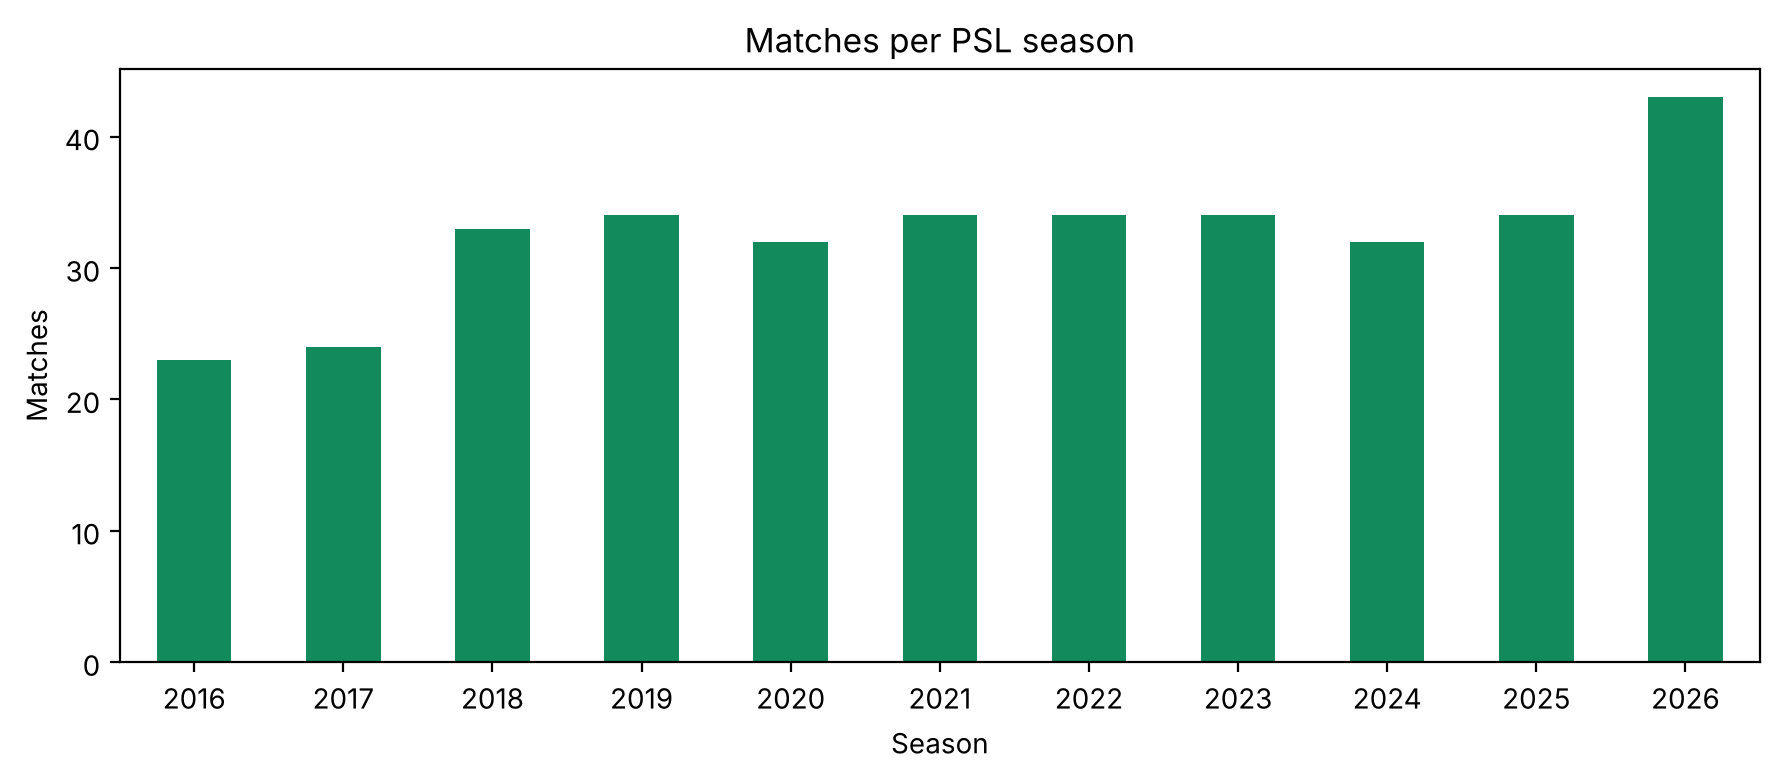

In [4]:
matches_per_season = matches.groupby("season").size()

matches_per_season.plot(kind="bar", figsize=(9, 4), color="#138a5c")
plt.title("Matches per PSL season")
plt.xlabel("Season")
plt.ylabel("Matches")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 3. Data quality
### 3.1 Missing values

In [5]:
print("Missing values in matches:")
display(matches.isnull().sum()[matches.isnull().sum() > 0])

print("Missing values in batting:")
display(batting.isnull().sum()[batting.isnull().sum() > 0])

print("Missing values in bowling:", bowling.isnull().sum().sum())

Missing values in matches:


home_score    1
away_score    2
winner        3
dtype: int64

Missing values in batting:


dismissal_type         1160
dismissal_bowler_id    1506
dtype: int64

Missing values in bowling: 0


**What the missing values mean:**
- `home_score` / `away_score` / `winner` are missing for the **3 abandoned matches**, where one team never batted. These are correctly treated as *no result* and not given a winner.
- `dismissal_type` is empty when the batter was **not out**.
- `dismissal_bowler_id` is also empty for **run outs**, because no bowler takes the wicket.

So the missing values are expected. They are not errors.

In [6]:
# The 3 abandoned (no result) matches
display(matches[matches["winner"].isnull()][["match_date", "home_team", "away_team", "home_score", "away_score"]])

,match_date,home_team,away_team,home_score,away_score
32,2017-02-17 00:00:00+00:00,Peshawar Zalmi,Quetta Gladiators,117.0,NaN
131,2020-03-06 00:00:00+00:00,Karachi Kings,Multan Sultans,NaN,102.0
300,2025-05-01 00:00:00+00:00,Lahore Qalandars,Quetta Gladiators,111.0,NaN


### 3.2 Duplicates
Each match should appear once, and each player should appear once per innings.

In [7]:
print("Duplicate match IDs:", matches["match_id"].duplicated().sum())
print("Duplicate batting records:", batting.duplicated(["match_id", "innings_number", "player_id"]).sum())
print("Duplicate bowling records:", bowling.duplicated(["match_id", "innings_number", "player_id"]).sum())

Duplicate match IDs: 0
Duplicate batting records: 0
Duplicate bowling records: 0


### 3.3 Same name, different player
Some names belong to **two different players** (different `player_id`). This is why we group by `player_id`, not by name.

In [8]:
ids_per_name = bowling.groupby("player_name")["player_id"].nunique()
display(ids_per_name[ids_per_name > 1].rename("different player IDs"))

player_name
Imran Khan         2
Khurram Shahzad    2
Mohammad Imran     2
Mohammad Irfan     2
Tayyab Abbas       2
Name: different player IDs, dtype: int64

### 3.4 Checking the numbers
We recalculate strike rate and economy ourselves and compare them with the API values.

Cricket overs are special: **3.4 overs = 3 overs + 4 balls = 22 balls**, not 3.4 decimal overs.

In [9]:
def overs_to_balls(overs):
    """3.4 overs -> 3 x 6 + 4 = 22 balls"""
    full_overs, extra_balls = str(overs).split(".")
    return int(full_overs) * 6 + int(extra_balls)

bowling["balls_bowled"] = bowling["overs"].apply(overs_to_balls)

# Strike rate = runs / balls x 100   (skip 0-ball innings to avoid dividing by zero)
faced = batting[batting["balls"] > 0]
our_strike_rate = (faced["runs"] / faced["balls"] * 100).round(2)
print("Strike rates that differ from the API:", (abs(our_strike_rate - faced["strike_rate"]) > 0.1).sum())

# Economy = runs conceded / balls x 6
our_economy = (bowling["runs"] / bowling["balls_bowled"] * 6).round(2)
print("Economy rates that differ from the API:", (abs(our_economy - bowling["economy"]) > 0.05).sum())

Strike rates that differ from the API: 0
Economy rates that differ from the API: 0


## 4. Match and team analysis
### 4.1 Wins and win percentage

,played,wins,win_%
Islamabad United,123,69,56.1
Peshawar Zalmi,124,69,55.6
Hyderabad Kingsmen,13,7,53.8
Multan Sultans,99,52,52.5
Quetta Gladiators,114,55,48.2
Lahore Qalandars,117,54,46.2
Karachi Kings,114,47,41.2
Rawalpindiz,10,1,10.0


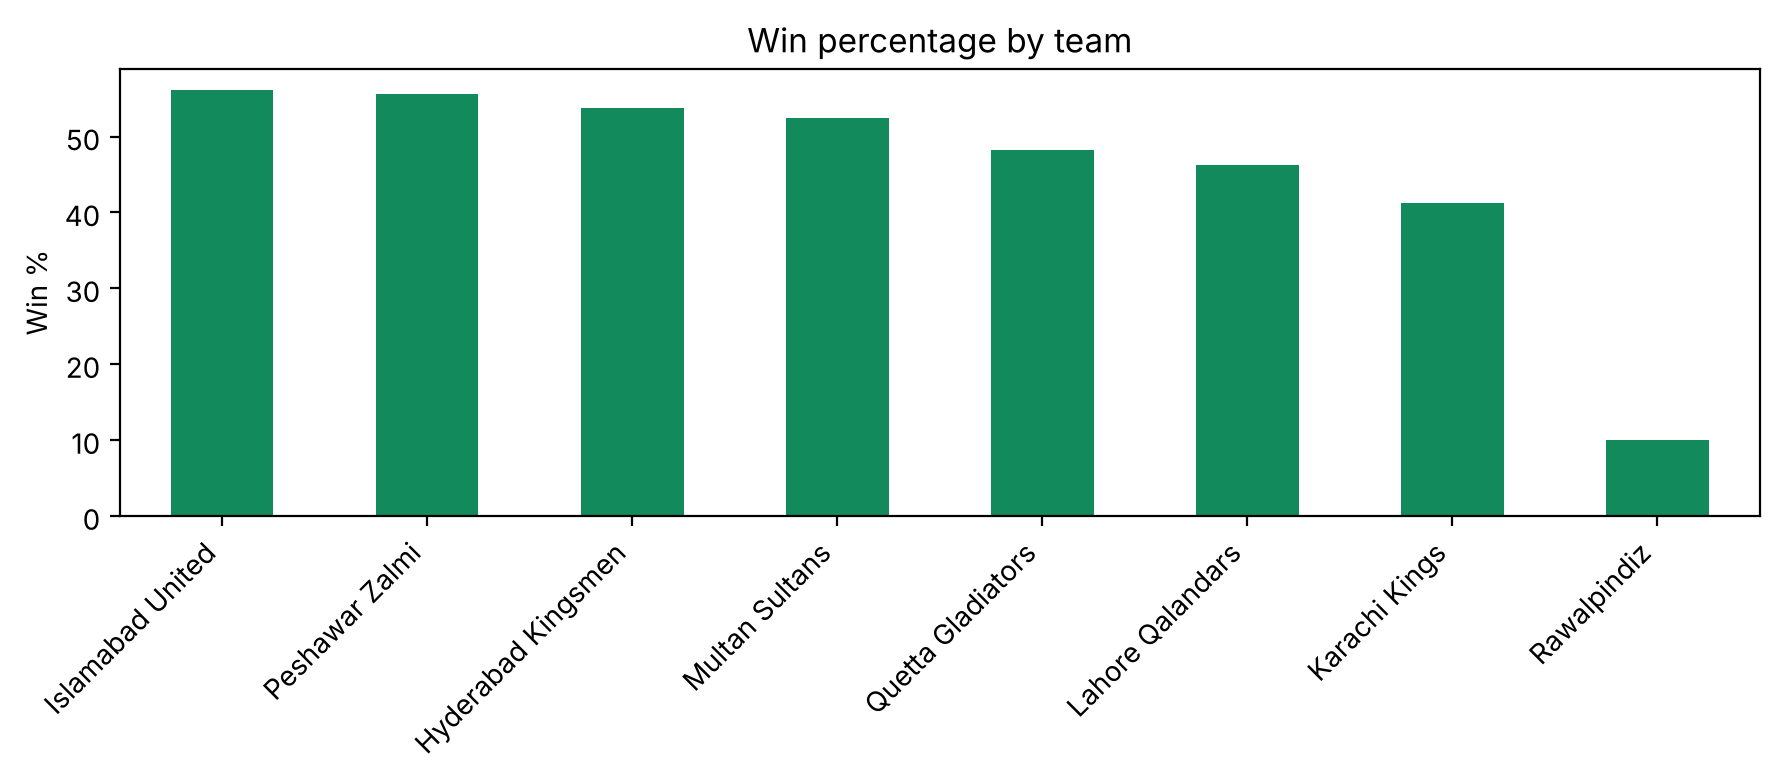

In [10]:
played = pd.concat([matches["home_team"], matches["away_team"]]).value_counts()
wins = matches["winner"].value_counts()

teams = pd.DataFrame({"played": played, "wins": wins}).fillna(0)
teams["win_%"] = (teams["wins"] / teams["played"] * 100).round(1)
teams = teams.sort_values("win_%", ascending=False)
display(teams)

teams["win_%"].plot(kind="bar", figsize=(9, 4), color="#138a5c")
plt.title("Win percentage by team")
plt.ylabel("Win %")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

> Hyderabad Kingsmen and Rawalpindiz joined in 2026 and have played very few matches, so their win % is less reliable than the other teams'.

### 4.2 Team scores

Average team score: 161.7
Highest team score: 263 | Lowest: 59


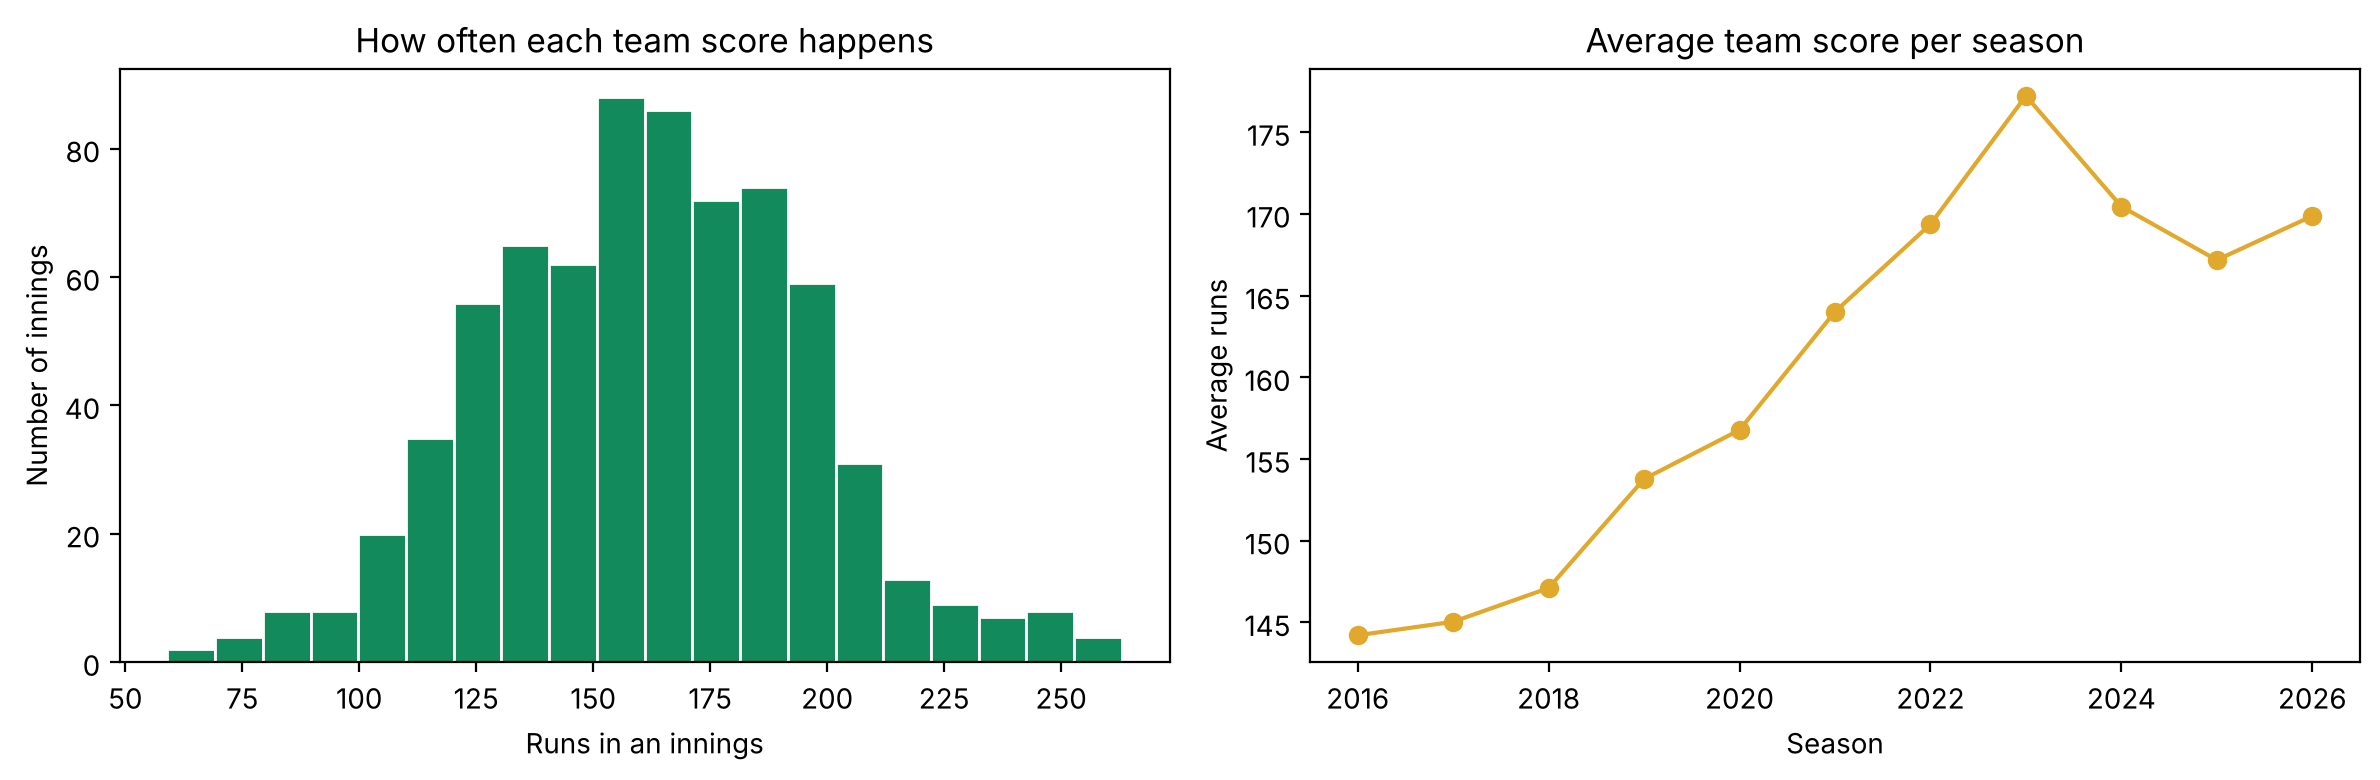

In [11]:
# Put home and away scores in one list of team scores
scores = pd.concat([
    matches[["season", "home_score"]].rename(columns={"home_score": "score"}),
    matches[["season", "away_score"]].rename(columns={"away_score": "score"}),
]).dropna()

print("Average team score:", round(scores["score"].mean(), 1))
print("Highest team score:", int(scores["score"].max()), "| Lowest:", int(scores["score"].min()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(scores["score"], bins=20, color="#138a5c", edgecolor="white")
axes[0].set_title("How often each team score happens")
axes[0].set_xlabel("Runs in an innings")
axes[0].set_ylabel("Number of innings")

scores.groupby("season")["score"].mean().plot(ax=axes[1], marker="o", color="#e0a92e")
axes[1].set_title("Average team score per season")
axes[1].set_xlabel("Season")
axes[1].set_ylabel("Average runs")

plt.tight_layout()
plt.show()

In [12]:
matches["total_runs"] = matches["home_score"] + matches["away_score"]

print("Highest-scoring matches:")
display(matches.sort_values("total_runs", ascending=False)
        [["match_date", "home_team", "home_score", "away_team", "away_score", "winner"]].head(5))

Highest-scoring matches:


,match_date,home_team,home_score,away_team,away_score,winner
241,2023-03-11 00:00:00+00:00,Multan Sultans,262.0,Quetta Gladiators,253.0,Multan Sultans
240,2023-03-10 00:00:00+00:00,Peshawar Zalmi,242.0,Multan Sultans,244.0,Multan Sultans
238,2023-03-08 00:00:00+00:00,Peshawar Zalmi,240.0,Quetta Gladiators,243.0,Quetta Gladiators
171,2021-06-17 00:00:00+00:00,Islamabad United,247.0,Peshawar Zalmi,232.0,Islamabad United
281,2025-04-12 00:00:00+00:00,Multan Sultans,234.0,Karachi Kings,236.0,Karachi Kings


## 5. Batting analysis
### 5.1 Top run scorers

,name,innings,runs,balls,fours,sixes,strike_rate
player_id,,,,,,,
bfc8ad13-00e2-55fd-8d18-be7d71000e9c,Babar Azam,109,4380,3377,479,80,129.7
fd6fbb76-5a63-5aec-ad93-0184a57f1dba,Fakhar Zaman,108,3370,2356,332,140,143.0
ea7e4f66-99e8-5f66-ab28-eaf6f291baf7,Mohammad Rizwan,92,2974,2323,277,75,128.0
443aadd9-48ae-5452-a471-fcde4ff5fb55,RR Rossouw,98,2609,1790,260,106,145.8
5abdc89e-4880-5782-a39f-1502af4c2ba6,Shoaib Malik,88,2350,1834,171,81,128.1
a94d476a-6d0e-5484-bb4a-02fce5d6ee79,Kamran Akmal,73,1942,1420,211,87,136.8
fabc773b-12e1-5bcf-9caf-6bbde27da5d6,Shan Masood,66,1870,1398,212,37,133.8
8f622f97-2fa9-5378-9a19-5a4b28c2507b,Mohammad Hafeez,73,1672,1356,152,63,123.3
cb9c1199-9766-55b6-bdf7-58a811c78bcc,C Munro,54,1633,1090,157,78,149.8


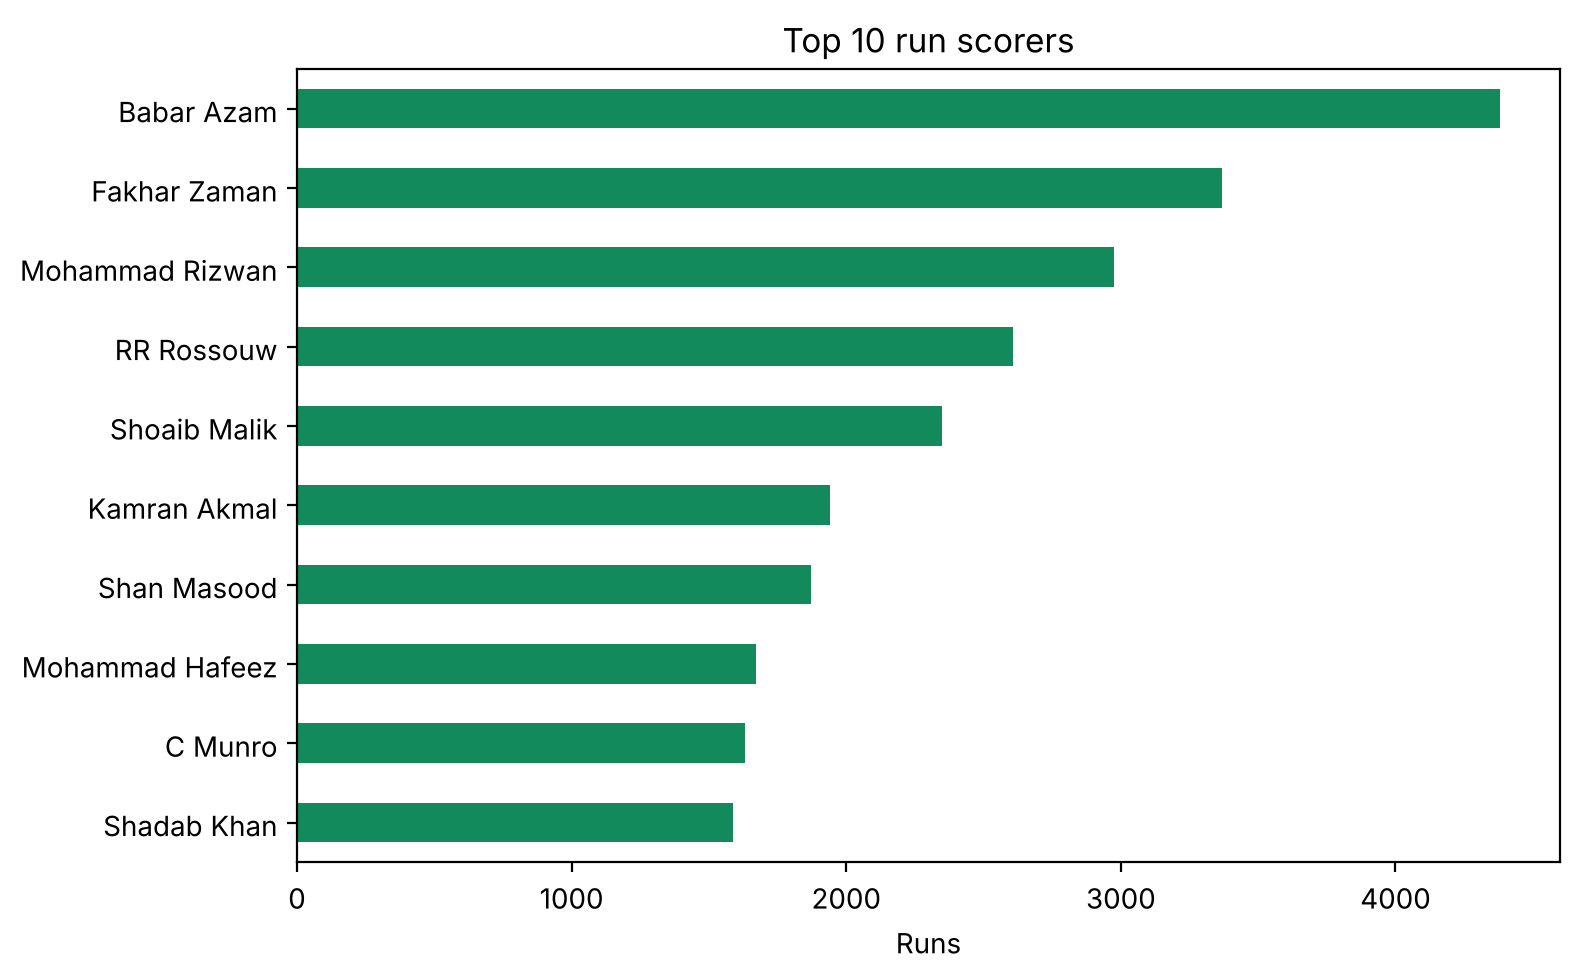

In [13]:
# Group by player_id so that two players with the same name are not mixed up
batters = batting.groupby("player_id").agg(
    name=("player_name", "first"),
    innings=("match_id", "count"),
    runs=("runs", "sum"),
    balls=("balls", "sum"),
    fours=("fours", "sum"),
    sixes=("sixes", "sum"),
)

# Overall strike rate = total runs / total balls x 100
batters["strike_rate"] = (batters["runs"] / batters["balls"] * 100).round(1)

top_run_scorers = batters.sort_values("runs", ascending=False).head(10)
display(top_run_scorers)

top_run_scorers.set_index("name")["runs"].sort_values().plot(kind="barh", figsize=(8, 5), color="#138a5c")
plt.title("Top 10 run scorers")
plt.xlabel("Runs")
plt.ylabel("")
plt.tight_layout()
plt.show()

### 5.2 Fastest scorers (strike rate)
A player who faced 3 balls can have a strike rate of 300, which tells us nothing. So we only include batters who faced **at least 300 balls**.

In [14]:
regular_batters = batters[batters["balls"] >= 300]
fastest = regular_batters.sort_values("strike_rate", ascending=False).head(10)
display(fastest[["name", "runs", "balls", "strike_rate"]])

,name,runs,balls,strike_rate
player_id,,,,
7c9a7fe4-2b07-5b79-b8d2-b70e2bfdaab7,TH David,605,337,179.5
328b3488-d6fb-53fe-b3dd-9a92b6803b45,BKG Mendis,693,412,168.2
721500f3-0254-54f8-ab4a-9e5ee7f9defb,Mohammad Haris,1111,666,166.8
83e24218-4ddb-529b-84a5-25ac3e0ff188,L Ronchi,1020,614,166.1
d470a09a-614b-5550-8edd-16f176dc89f9,KA Pollard,1149,708,162.3
522f9747-33a6-51fb-996c-18eb965cd1b8,D Wiese,629,389,161.7
1603fdb2-2c14-5bee-8104-47d91af65381,Usman Khan,1349,852,158.3
5ff9cac0-09da-5292-a4f2-ae7f9a969338,BCJ Cutting,481,306,157.2
abe264dd-4829-5375-835d-0911dc36c439,Asif Ali,1296,827,156.7


### 5.3 Boundaries

Total fours: 10013 | Total sixes: 4544


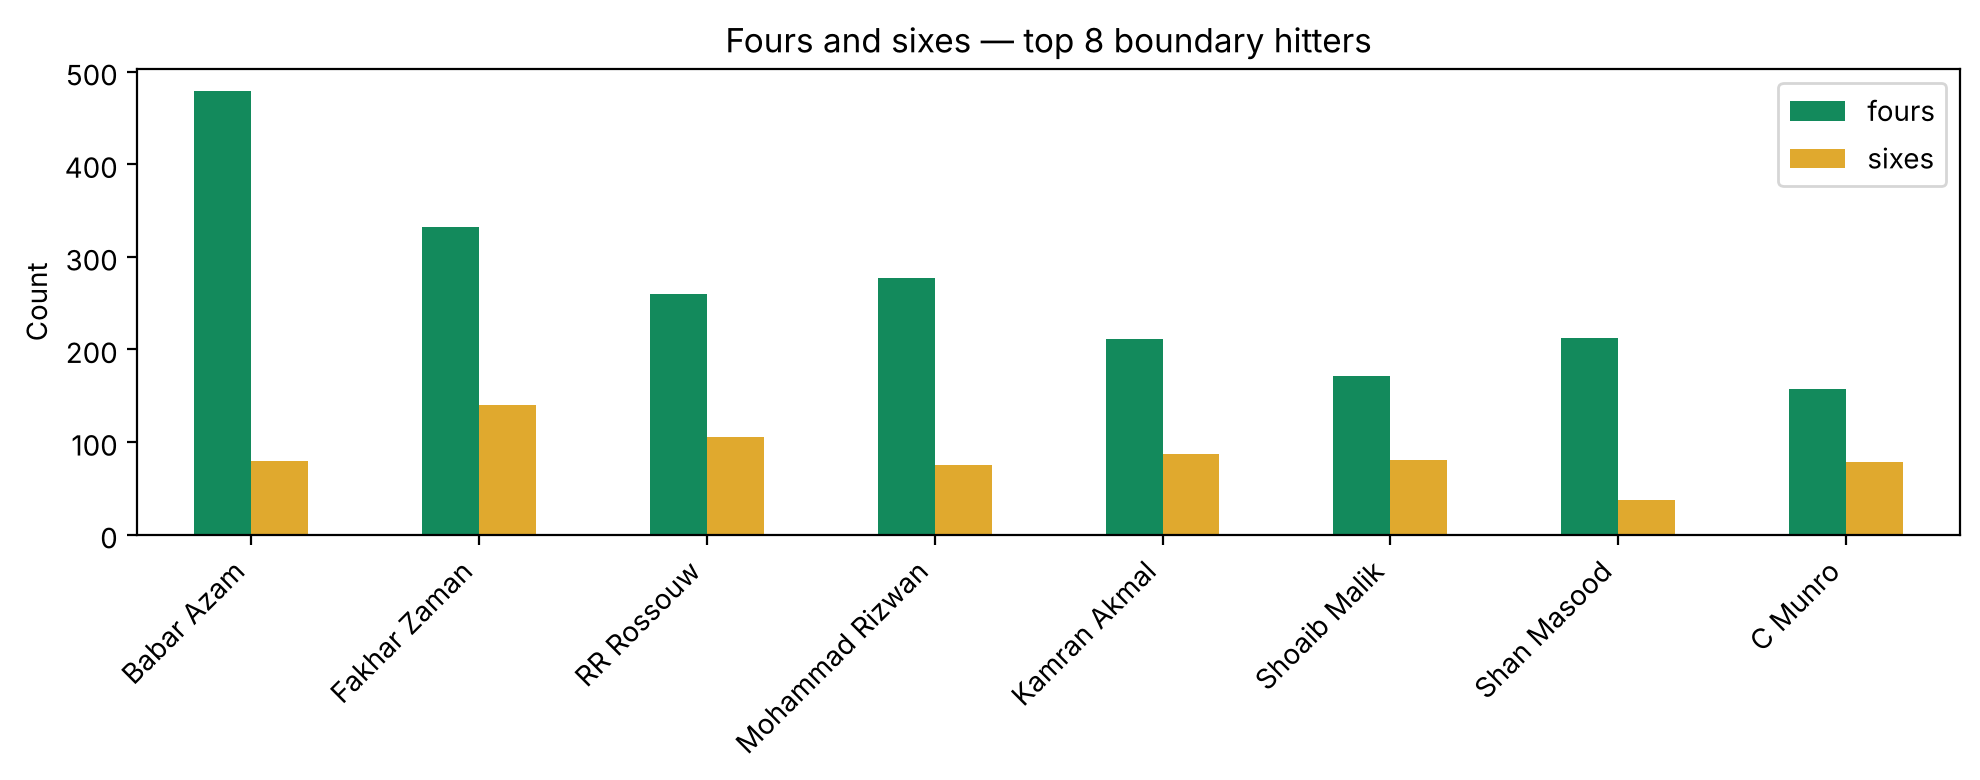

Sixes per match each season:


season
2016    10.0
2017    10.8
2018    12.7
2019    11.1
2020    12.1
2021    12.9
2022    12.8
2023    14.6
2024    12.1
2025    15.3
2026    13.7
dtype: float64

In [15]:
print("Total fours:", batting["fours"].sum(), "| Total sixes:", batting["sixes"].sum())

top_boundaries = batters.assign(boundaries=batters["fours"] + batters["sixes"])
top_boundaries = top_boundaries.sort_values("boundaries", ascending=False).head(8)

top_boundaries.set_index("name")[["fours", "sixes"]].plot(kind="bar", figsize=(10, 4), color=["#138a5c", "#e0a92e"])
plt.title("Fours and sixes — top 8 boundary hitters")
plt.ylabel("Count")
plt.xlabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Are sixes becoming more common?
batting_with_season = batting.merge(matches[["match_id", "season"]], on="match_id")
sixes_per_match = batting_with_season.groupby("season")["sixes"].sum() / matches.groupby("season").size()
print("Sixes per match each season:")
display(sixes_per_match.round(1))

### 5.4 How batters get out

dismissal_type
caught                   2760
not out                  1160
bowled                    847
run out                   341
lbw                       334
caught and bowled         122
stumped                    89
hit wicket                  8
retired hurt                3
retired out                 1
obstructing the field       1
Name: count, dtype: int64

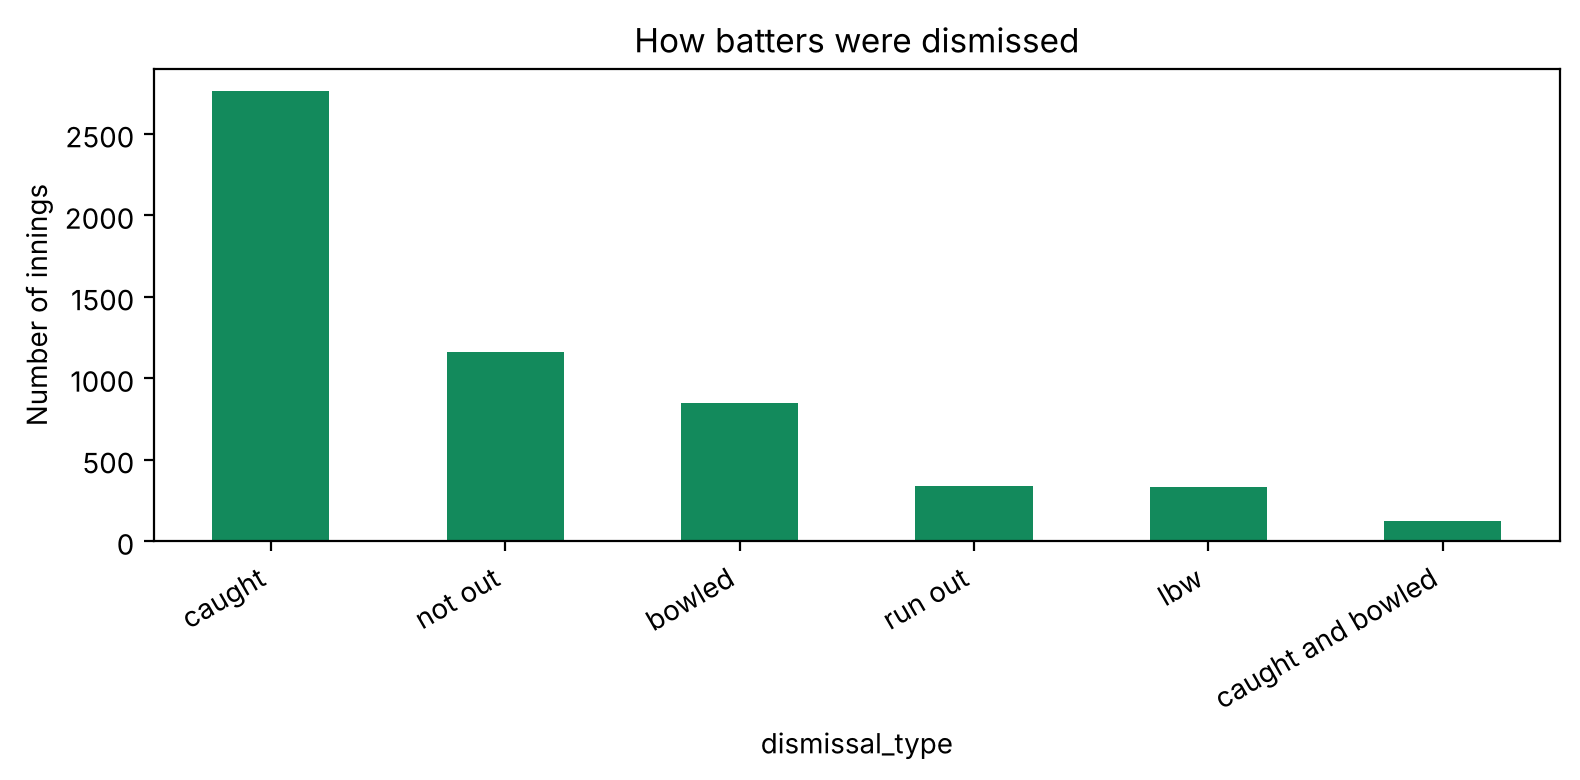

In [16]:
dismissals = batting["dismissal_type"].fillna("not out").value_counts()
display(dismissals)

dismissals.head(6).plot(kind="bar", figsize=(8, 4), color="#138a5c")
plt.title("How batters were dismissed")
plt.ylabel("Number of innings")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 6. Bowling analysis
### 6.1 Leading wicket-takers

,name,wickets,runs_conceded,balls,overs,economy
player_id,,,,,,
6c4795fe-afa4-5e7c-a8e9-d8b62b31daad,Hasan Ali,140,3151,2292,382.0,8.25
0e915f20-e7f2-5d82-a847-b2d151a7798e,Shaheen Shah Afridi,138,2777,2088,348.0,7.98
26c4baa5-18a5-5972-8494-323ec67fc56e,Shadab Khan,122,2788,2190,365.0,7.64
48c71eff-55ca-5012-a131-e31036e59010,Wahab Riaz,111,2539,1955,325.5,7.79
afbb2d6b-e1a0-5f16-806b-7b6d2a5dfb87,Faheem Ashraf,104,2542,1743,290.3,8.75
85568003-feb9-5a09-acc9-2890785b0ea9,Mohammad Amir,97,2650,2049,341.3,7.76
e1259a98-a6bd-5cb8-af87-976f5496e88c,Haris Rauf,95,2676,1717,286.1,9.35
cbae2a0c-7db0-541f-b471-da3e53623fd7,Imad Wasim,89,2548,2156,359.2,7.09
682c7e48-042e-5e37-b016-0530d0dece47,Mohammad Nawaz (3),80,2358,1792,298.4,7.90


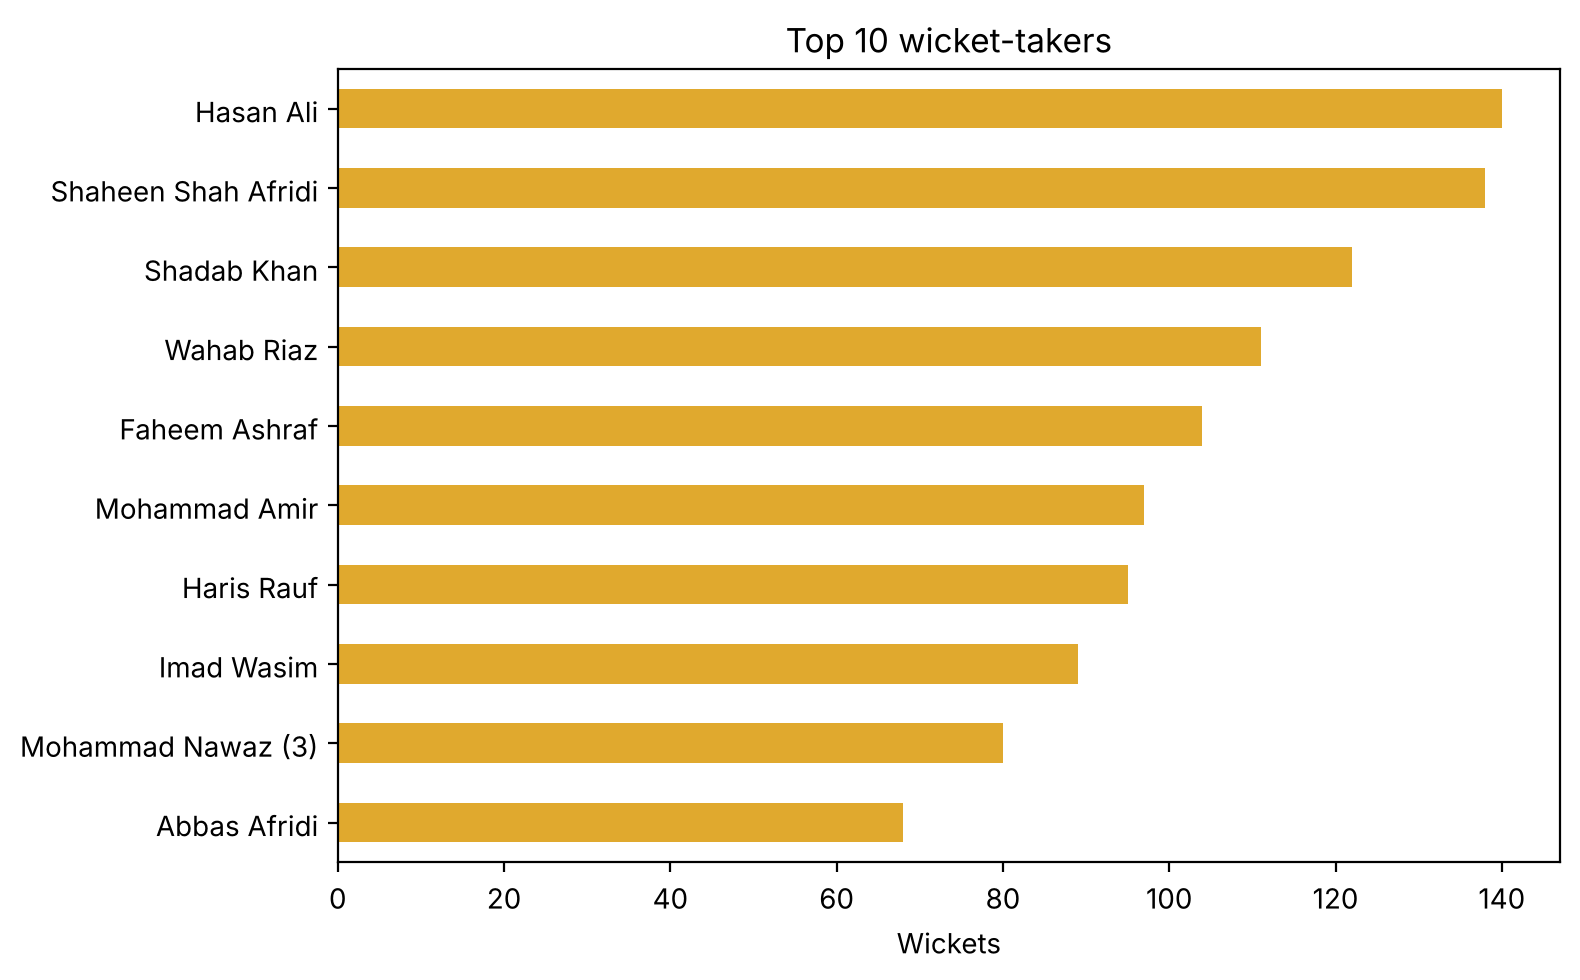

In [17]:
bowlers = bowling.groupby("player_id").agg(
    name=("player_name", "first"),
    wickets=("wickets", "sum"),
    runs_conceded=("runs", "sum"),
    balls=("balls_bowled", "sum"),
)
bowlers["overs"] = bowlers["balls"] // 6 + (bowlers["balls"] % 6) / 10   # e.g. 22 balls -> 3.4
bowlers["economy"] = (bowlers["runs_conceded"] / bowlers["balls"] * 6).round(2)

top_wicket_takers = bowlers.sort_values("wickets", ascending=False).head(10)
display(top_wicket_takers)

top_wicket_takers.set_index("name")["wickets"].sort_values().plot(kind="barh", figsize=(8, 5), color="#e0a92e")
plt.title("Top 10 wicket-takers")
plt.xlabel("Wickets")
plt.ylabel("")
plt.tight_layout()
plt.show()

### 6.2 Most economical bowlers
We only include bowlers with **at least 50 overs (300 balls)**, so a single good over does not top the list.

,name,overs,wickets,economy
player_id,,,,
63b7e7e8-0ddd-516c-9bae-b6d9d5040a96,Rashid Khan,111.0,44,6.14
2ddf68e9-b087-5ff8-9e83-347a1d9afb30,SP Narine,67.0,21,6.25
8f622f97-2fa9-5378-9a19-5a4b28c2507b,Mohammad Hafeez,74.1,18,6.88
0099abed-5146-5055-99f5-70d7590382ad,Zulfiqar Babar,72.0,15,6.93
5bbbfca9-3487-5b92-9670-bb2c8f3a2e1b,Mohammad Sami,128.0,43,6.95
02b2f1bd-352e-5f25-90ab-44c39e7b93c6,Mohammad Irfan,192.3,45,6.97
ad24007c-4fad-59b0-8267-03ebb04c9673,Imran Tahir,156.0,56,7.05
cbae2a0c-7db0-541f-b471-da3e53623fd7,Imad Wasim,359.2,89,7.09
5abdc89e-4880-5782-a39f-1502af4c2ba6,Shoaib Malik,110.5,17,7.15


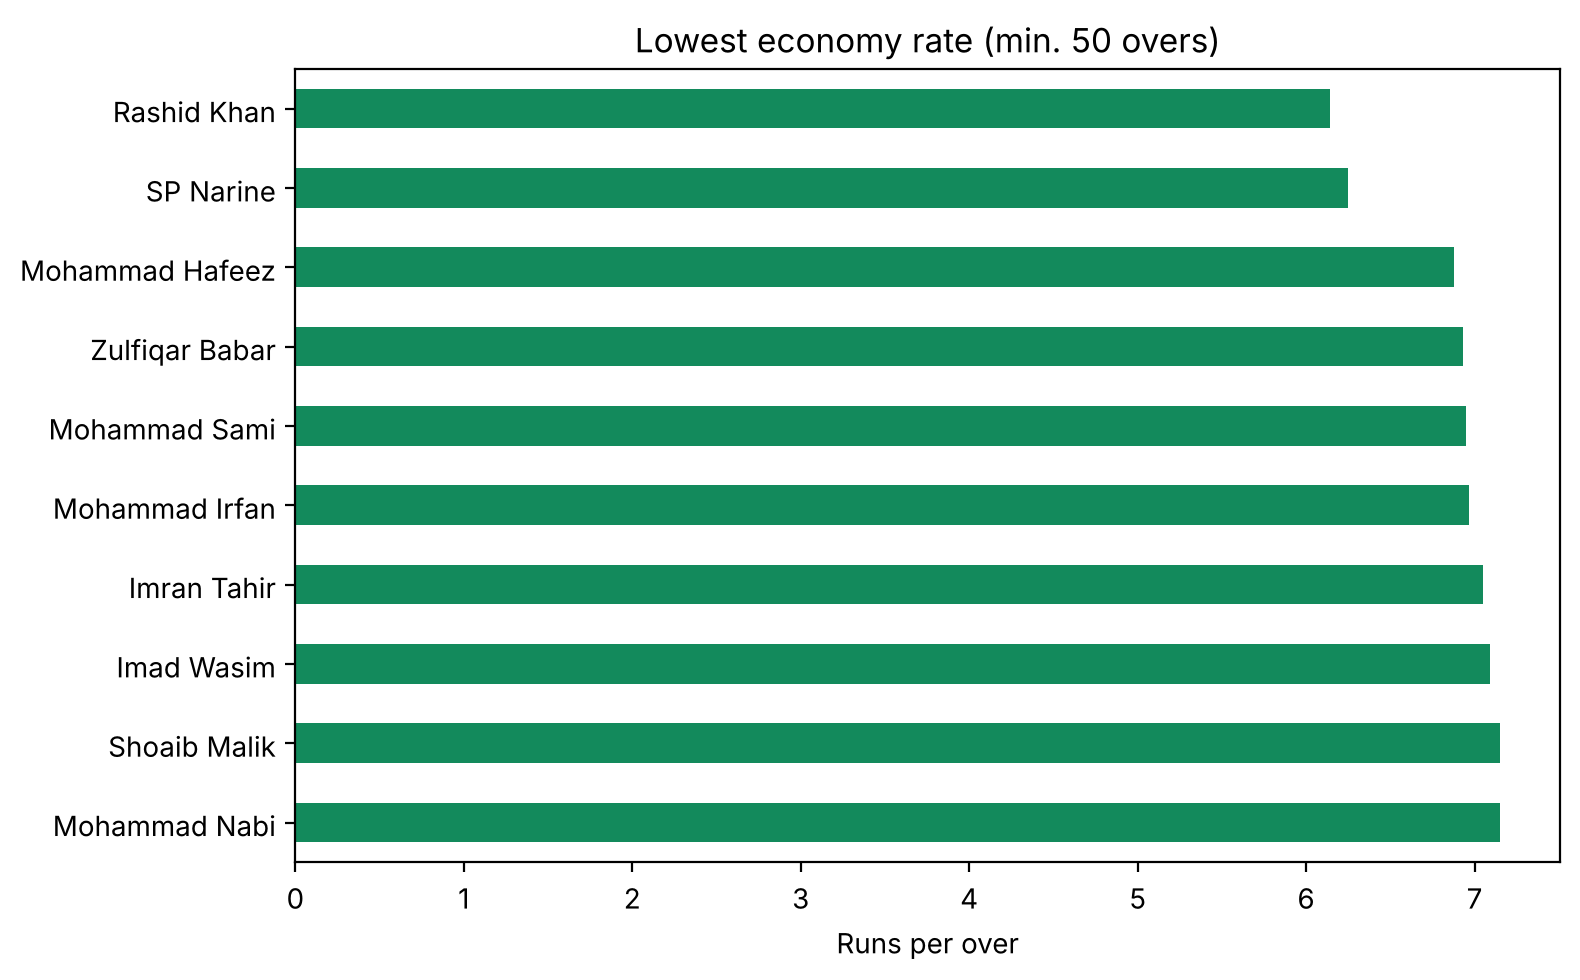

In [18]:
regular_bowlers = bowlers[bowlers["balls"] >= 300]
most_economical = regular_bowlers.sort_values("economy").head(10)
display(most_economical[["name", "overs", "wickets", "economy"]])

most_economical.set_index("name")["economy"].sort_values(ascending=False).plot(kind="barh", figsize=(8, 5), color="#138a5c")
plt.title("Lowest economy rate (min. 50 overs)")
plt.xlabel("Runs per over")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 7. Key findings

1. **The data is clean.** It has no duplicate matches or player records, and the strike rates and economy rates from the API match our own calculations. The only missing values are expected ones (not-out batters, run outs and 3 abandoned matches).
2. **Scoring has grown a lot.** The average team score rose from about **144 in 2016 to about 170** in recent seasons, peaking at **177 in 2023**. Sixes per match went from about **10 to 15**.
3. **Islamabad United and Peshawar Zalmi** are the most successful of the long-standing teams, each winning about **56%** of their matches. **Karachi Kings** have the lowest win % among the original teams (about **41%**).
4. **Babar Azam** is the leading run scorer (**4,380 runs**), and **Hasan Ali** is the leading wicket-taker (**140 wickets**).
5. **Caught** is the most common dismissal (about **49%** of innings), followed by **bowled** (about **15%**).
6. Using **minimum thresholds** (300 balls for strike rate, 50 overs for economy) gives fair rankings. Without them, players with one or two short innings would wrongly top the lists.
7. Grouping by **player_id** matters, because names like *Mohammad Irfan* and *Khurram Shahzad* belong to two different players each.